# s1 single-flow PHY sweep — PRR / HARQ vs N_Rx and distance

Read-only analysis of the in-progress sweep at `../../../../tmp/`.

Sweep config: single flow `platoon_control` (port 8001), `maxNumTx=1`, single-seed (seed=2),
6 group sizes (`n_ues` ∈ {2,4,8,12,16,20}) × 168 PHY combos (μ, w, MCS) = 856 runs.

**Sections**
0. Setup & data loading
1. PRR variance vs N_Rx per PHY config
2. Effect of each PHY knob on PRR-vs-N_Rx
3. Optimal MCS per receiver vs distance from Tx
4. ACK / NACK counts vs distance from Tx
5. Bonus analyses (cliff diagnosis, contention coupling, HARQ↔BLER consistency, fairness)

## §0 — Setup & data loading

In [1]:
import gzip, os, shutil, sqlite3, sys, tempfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(context='notebook', style='whitegrid')
plt.rcParams['figure.dpi'] = 110

NB_DIR = Path.cwd()
REPO = NB_DIR.parents[3]
TMP = REPO / 'tmp'
SCRIPTS = REPO / 'scratch_overlay' / 'adaptive-phy-eval' / 'scripts'
sys.path.insert(0, str(SCRIPTS))
import per_rx_prr as prx  # for load_distances() and parse_stem()

print('repo:', REPO)
print('tmp :', TMP, 'exists' if TMP.exists() else 'MISSING')

repo: /Users/hadih/Documents/groupcast-adaptation-ns3
tmp : /Users/hadih/Documents/groupcast-adaptation-ns3/tmp exists


In [2]:
# Run per_rx_prr.py if its output is missing or older than the newest db.gz
per_rx_csv = TMP / '_per_rx_prr.csv'
if not per_rx_csv.exists():
    print('extracting per-rx PRR ...')
    !python3 {SCRIPTS}/per_rx_prr.py --tmp {TMP} --scen s1
else:
    print('using cached', per_rx_csv)

using cached /Users/hadih/Documents/groupcast-adaptation-ns3/tmp/_per_rx_prr.csv


In [3]:
# Inline per-receiver HARQ extractor (joins ACK/NACK with SUMO distance from Tx)
SUMO_ROOT = SCRIPTS.parent / 'sumo'

def extract_per_rx_harq(tmp_dir: Path, sumo_root: Path, scen='s1',
                        out_csv: Path | None = None, force=False) -> pd.DataFrame:
    out_csv = out_csv or (tmp_dir / '_per_rx_harq.csv')
    if out_csv.exists() and not force:
        print('using cached', out_csv)
        return pd.read_csv(out_csv)
    rows = []
    dist_cache = {}
    db_files = sorted(tmp_dir.glob('*.db.gz'))
    for i, pf in enumerate(db_files, 1):
        meta = prx.parse_stem(pf.name[:-len('.db.gz')])
        if meta is None or meta['scen'] != scen:
            continue
        n_ues = prx.num_ues_from_cond(meta['scen'], meta['cond'])
        key = (meta['scen'], meta['cond'])
        if key not in dist_cache:
            dist_cache[key] = prx.load_distances(sumo_root, *key)
        distances = dist_cache[key]
        # decompress -> open
        tf = tempfile.NamedTemporaryFile(suffix='.db', delete=False)
        with gzip.open(pf, 'rb') as fin:
            shutil.copyfileobj(fin, tf, length=1<<20)
        tf.close()
        try:
            con = sqlite3.connect(tf.name)
            agg = {}
            try:
                for rxn, status, c in con.execute(
                    "SELECT rxNodeId, status, COUNT(*) FROM slHarqFeedback "
                    "WHERE timeSec > 3.0 GROUP BY rxNodeId, status"
                ):
                    rxn = int(rxn); s = str(status).strip().upper()
                    agg.setdefault(rxn, {'ack':0,'nack':0})
                    if s == 'ACK':  agg[rxn]['ack']  += int(c)
                    elif s == 'NACK': agg[rxn]['nack'] += int(c)
            except sqlite3.OperationalError:
                pass
            for rxn, v in agg.items():
                d = distances[rxn] if (distances and rxn < len(distances)) else None
                tot = v['ack'] + v['nack']
                rows.append({
                    'stem': pf.name[:-len('.db.gz')],
                    **meta, 'n_ues': n_ues,
                    'rx_node': rxn, 'distance_m': d,
                    'ack': v['ack'], 'nack': v['nack'],
                    'ack_rate': (v['ack']/tot) if tot else None,
                })
            con.close()
        finally:
            os.unlink(tf.name)
        if i % 100 == 0:
            print(f'  {i}/{len(db_files)} processed, {len(rows)} rows so far')
    df = pd.DataFrame(rows)
    df.to_csv(out_csv, index=False)
    print('wrote', out_csv, 'rows=', len(df))
    return df

df_harq = extract_per_rx_harq(TMP, SUMO_ROOT, scen='s1')
df_harq.head()

using cached /Users/hadih/Documents/groupcast-adaptation-ns3/tmp/_per_rx_harq.csv


,stem,scen,cond,mu,w,mcs,seed,n_ues,rx_node,distance_m,ack,nack,ack_rate
0,s1_nrx02_mu0_w100_mcs0_seed2,s1,nrx02,0,100,0,2,2,0,0.0,675,0,1.0
1,s1_nrx02_mu0_w100_mcs0_seed2,s1,nrx02,0,100,0,2,2,1,20.0,689,0,1.0
2,s1_nrx02_mu0_w100_mcs11_seed2,s1,nrx02,0,100,11,2,2,0,0.0,604,0,1.0
3,s1_nrx02_mu0_w100_mcs11_seed2,s1,nrx02,0,100,11,2,2,1,20.0,603,0,1.0
4,s1_nrx02_mu0_w100_mcs13_seed2,s1,nrx02,0,100,13,2,2,0,0.0,604,0,1.0


In [4]:
# Load all three frames and filter to s1 + active flow
df_sum = pd.read_csv(TMP / '_summary.csv')
df_rx  = pd.read_csv(TMP / '_per_rx_prr.csv')

df_sum = df_sum[df_sum['scen']=='s1'].copy()
df_rx  = df_rx[(df_rx['scen']=='s1') & (df_rx['flow']=='cam')].copy()
df_harq = df_harq[df_harq['scen']=='s1'].copy() if 'scen' in df_harq.columns else df_harq

# Use cam-flow PRR as group PRR (single-flow sweep)
df_sum['prr'] = df_sum['prr_cam']

print('df_sum  :', df_sum.shape)
print('df_rx   :', df_rx.shape)
print('df_harq :', df_harq.shape)
print('PHY combos:', df_sum.groupby(['mu','w','mcs']).ngroups)
print('group sizes:', sorted(df_sum['n_ues'].unique()))

df_sum  : (856, 27)
df_rx   : (7532, 14)
df_harq : (7532, 13)
PHY combos: 168
group sizes: [np.int64(2), np.int64(4), np.int64(8), np.int64(12), np.int64(16), np.int64(20)]


In [5]:
# Sanity: HARQ totals must reconcile with summary CSV
if not df_harq.empty:
    a = df_harq.groupby('stem')[['ack','nack']].sum()
    b = df_sum.set_index('stem')[['harq_ack','harq_nack']]
    j = a.join(b, how='inner')
    diff = (j['ack'] - j['harq_ack']).abs().sum() + (j['nack'] - j['harq_nack']).abs().sum()
    print(f'reconciliation diff (should be 0): {diff}')

reconciliation diff (should be 0): 472185


## §1 — PRR variance vs N_Rx per PHY config
Within-group dispersion (per-rx PRR) and cross-group dispersion (group PRR std over N_Rx).

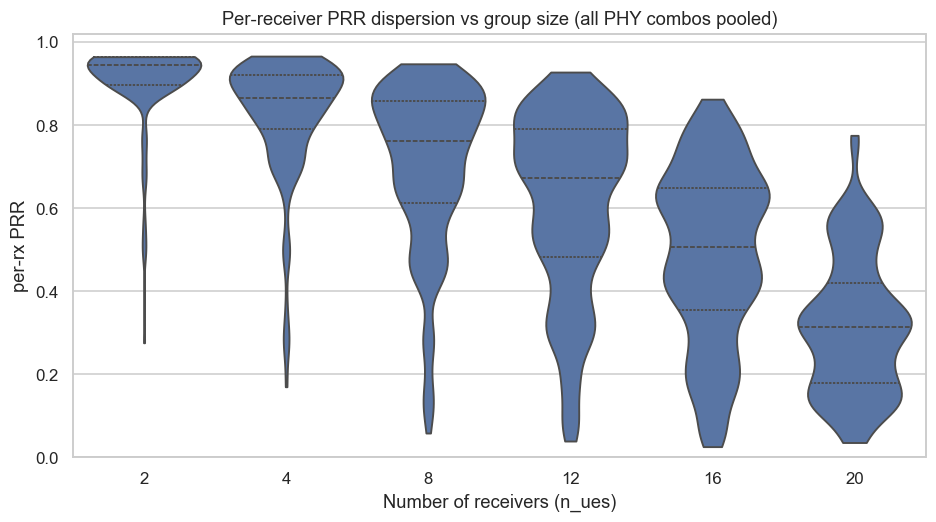

In [6]:
# 1a — within-group PRR dispersion (per-rx PRR) by N_Rx
fig, ax = plt.subplots(figsize=(10, 5))
sns.violinplot(data=df_rx, x='n_ues', y='prr_rx', inner='quartile',
               order=sorted(df_rx['n_ues'].unique()), cut=0, density_norm='width', ax=ax)
ax.set_title('Per-receiver PRR dispersion vs group size (all PHY combos pooled)')
ax.set_xlabel('Number of receivers (n_ues)')
ax.set_ylabel('per-rx PRR')
ax.set_ylim(0, 1.02)
plt.show()

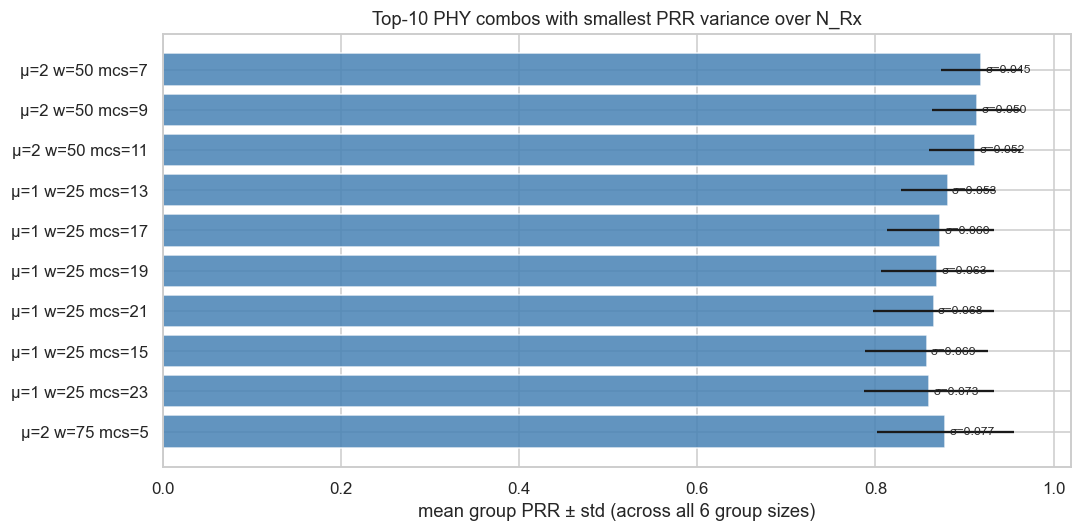

,mu,w,mcs,prr_mean,prr_std,prr_min,prr_max,n,range
129,2,50,7,0.918953,0.045193,0.855081,0.964410,5,0.109329
130,2,50,9,0.913839,0.050018,0.843022,0.964410,5,0.121388
131,2,50,11,0.911635,0.051664,0.838728,0.964410,5,0.125681
62,1,25,13,0.881098,0.052653,0.815546,0.943576,5,0.128030
64,1,25,17,0.872866,0.060007,0.797244,0.943576,5,0.146333
65,1,25,19,0.869467,0.063338,0.788877,0.943576,5,0.154699
66,1,25,21,0.865281,0.067670,0.777914,0.943576,5,0.165662
63,1,25,15,0.857420,0.068800,0.762478,0.943576,6,0.181098
67,1,25,23,0.860341,0.072841,0.764950,0.943576,5,0.178626
142,2,75,5,0.878637,0.076949,0.776532,0.964410,5,0.187877


In [7]:
# 1b — cross-group PRR std per (mu, w, mcs); top-10 most robust PHYs
stat = (df_sum.groupby(['mu','w','mcs'])['prr']
         .agg(prr_mean='mean', prr_std='std', prr_min='min', prr_max='max', n='size')
         .reset_index())
stat['range'] = stat['prr_max'] - stat['prr_min']
robust = stat[stat['n']>=5].nsmallest(10, 'prr_std')
fig, ax = plt.subplots(figsize=(10, 5))
labels = robust.apply(lambda r: f"μ={int(r['mu'])} w={int(r['w'])} mcs={int(r['mcs'])}", axis=1)
ax.barh(labels, robust['prr_mean'], xerr=robust['prr_std'], color='steelblue', alpha=0.85)
ax.invert_yaxis()
ax.set_xlim(0, 1.02)
ax.set_xlabel('mean group PRR ± std (across all 6 group sizes)')
ax.set_title('Top-10 PHY combos with smallest PRR variance over N_Rx')
for y, (_, r) in enumerate(robust.iterrows()):
    ax.text(r['prr_mean']+0.005, y, f"σ={r['prr_std']:.3f}", va='center', fontsize=8)
plt.tight_layout(); plt.show()
robust

## §2 — Effect of each PHY knob on PRR-vs-N_Rx

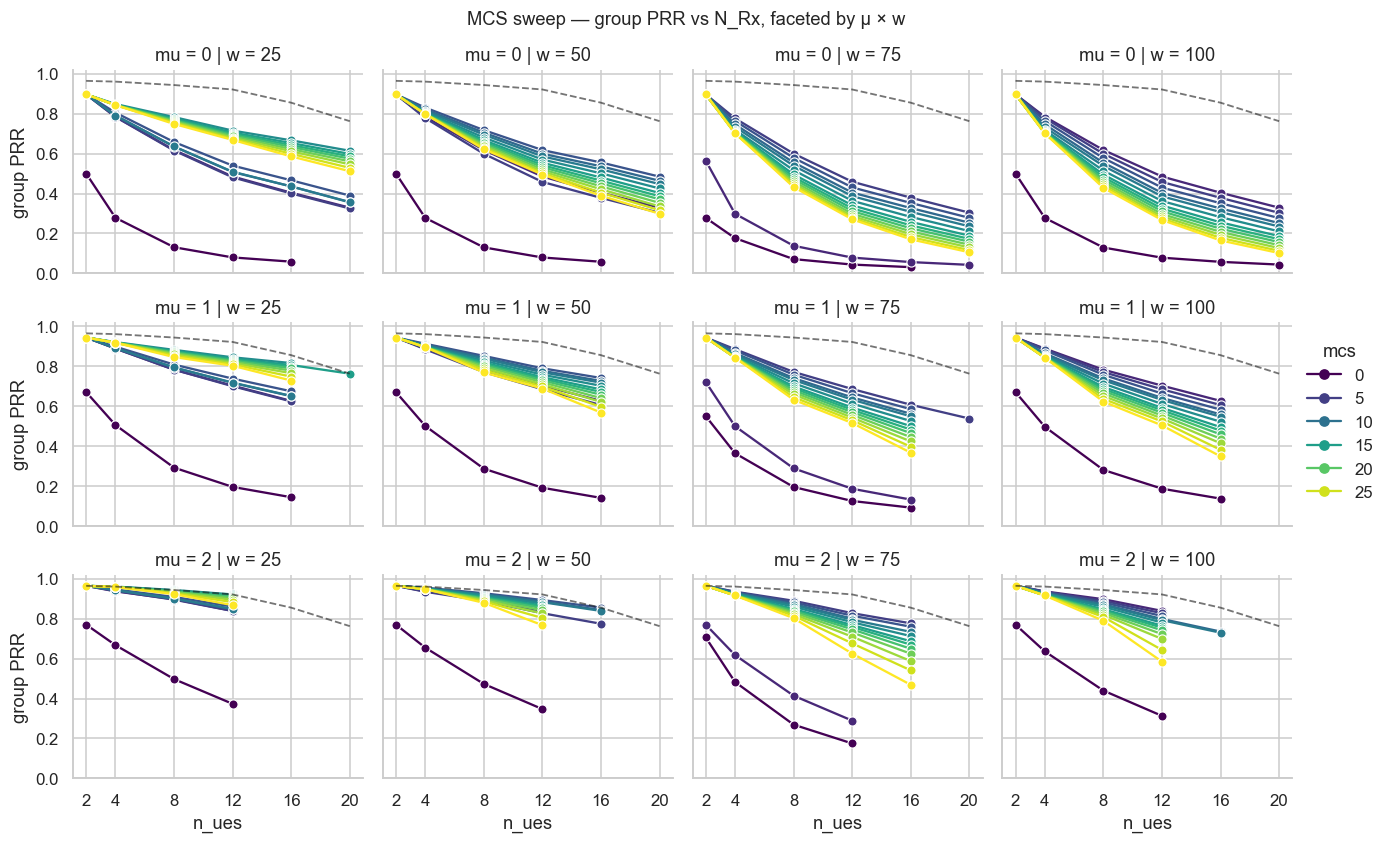

In [8]:
def best_envelope(df):
    return df.groupby('n_ues')['prr'].max().reset_index()

def facet_lines(df, hue, row, col, title, palette='viridis'):
    g = sns.relplot(data=df, x='n_ues', y='prr', hue=hue, row=row, col=col,
                    kind='line', marker='o', palette=palette, height=2.5, aspect=1.2,
                    facet_kws={'sharey': True})
    env = best_envelope(df)
    for ax in g.axes.flat:
        ax.plot(env['n_ues'], env['prr'], 'k--', lw=1.2, alpha=0.6, label='best PHY @ N')
        ax.set_ylim(0, 1.02); ax.set_xticks(sorted(df['n_ues'].unique()))
    g.set_axis_labels('n_ues', 'group PRR')
    g.figure.suptitle(title, y=1.02, fontsize=12)
    plt.show()

facet_lines(df_sum, hue='mcs', row='mu', col='w',
            title='MCS sweep — group PRR vs N_Rx, faceted by μ × w')

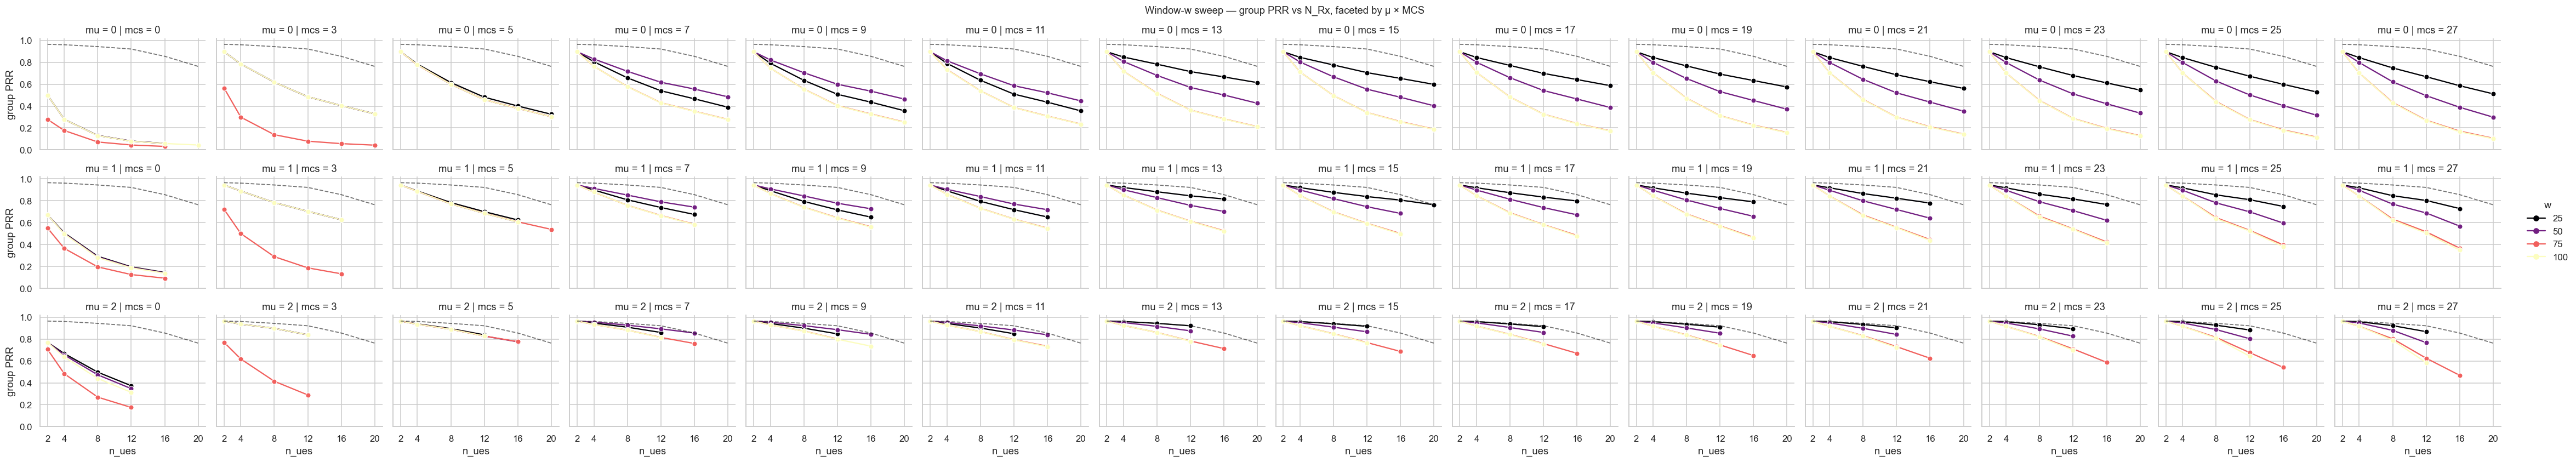

In [9]:
# Window (w) sweep: aggregate over MCS — too many MCS values to facet directly
facet_lines(df_sum, hue='w', row='mu', col='mcs',
            title='Window-w sweep — group PRR vs N_Rx, faceted by μ × MCS', palette='magma')

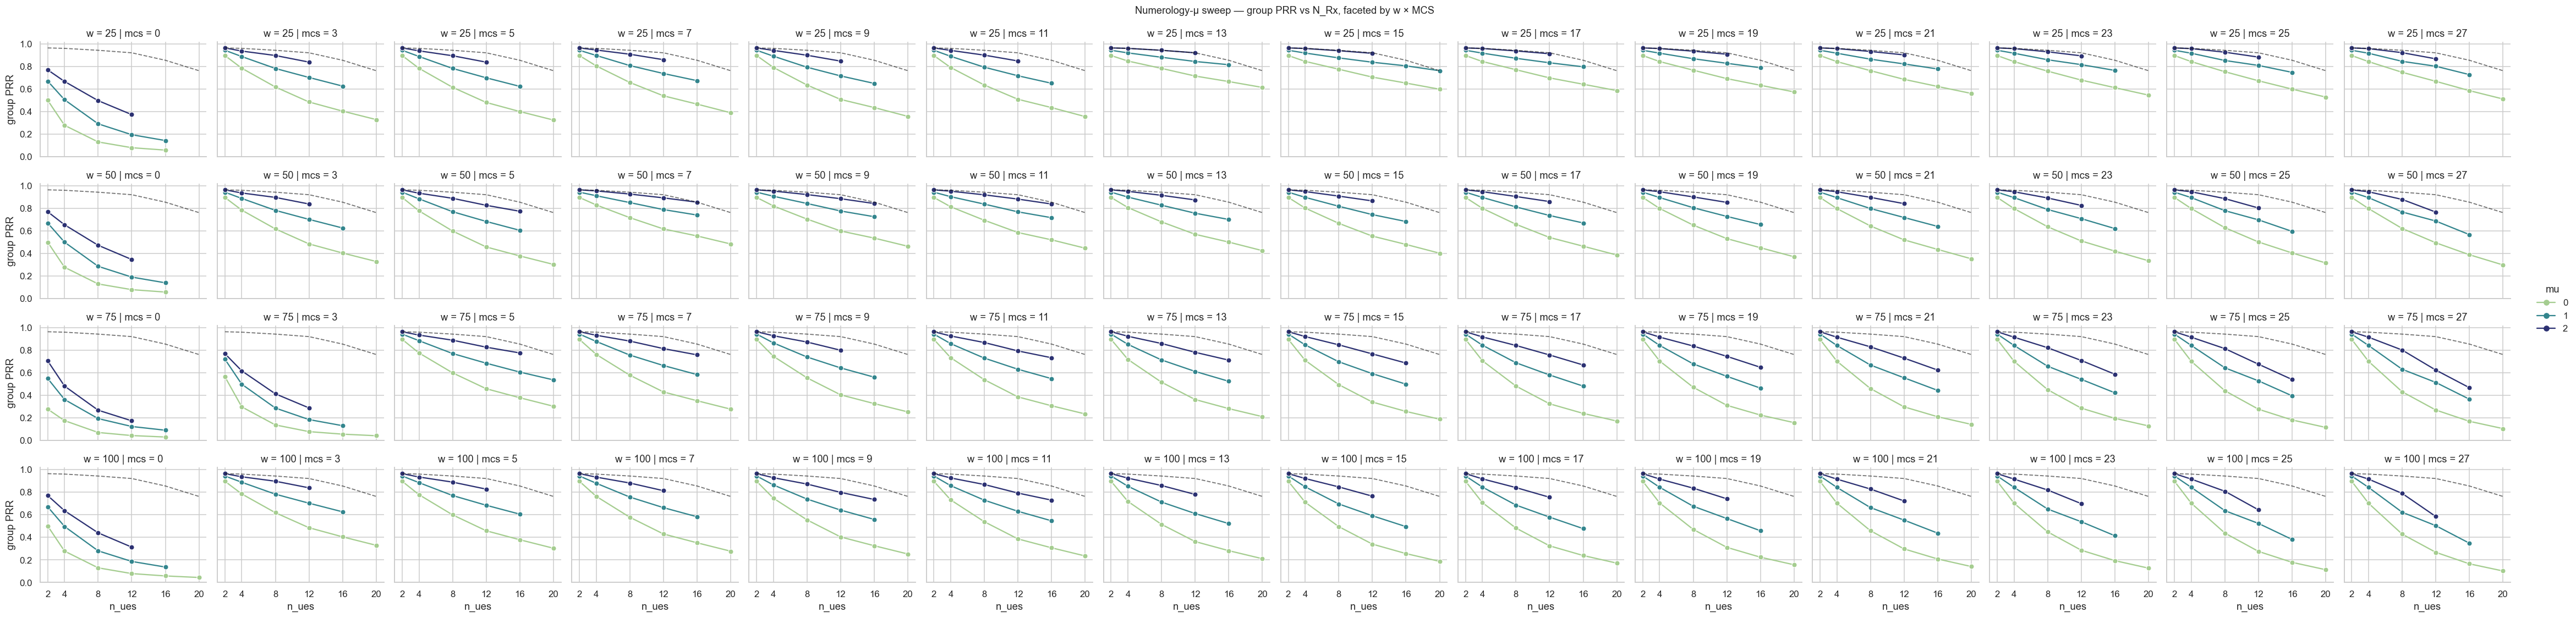

In [10]:
facet_lines(df_sum, hue='mu', row='w', col='mcs',
            title='Numerology-μ sweep — group PRR vs N_Rx, faceted by w × MCS', palette='crest')

In [11]:
# Compact summary: best (mu,w,mcs) at each N_Rx
best_per_n = (df_sum.sort_values('prr', ascending=False)
                    .groupby('n_ues').head(3)
                    .sort_values(['n_ues','prr'], ascending=[True, False])
                    [['n_ues','mu','w','mcs','prr','coll_rate','pssch_bler','sinr_mean_db']])
best_per_n

,n_ues,mu,w,mcs,prr,coll_rate,pssch_bler,sinr_mean_db
132,2,2,25,21,0.964410,0.007500,0.000000,45.380611
148,2,2,50,25,0.964410,0.020000,0.000000,42.394521
124,2,2,100,7,0.964410,0.036667,0.000000,39.382745
296,4,2,25,13,0.960576,0.022500,0.004971,43.557330
297,4,2,25,15,0.959491,0.022500,0.006196,43.557330
298,4,2,25,17,0.959274,0.022500,0.006412,43.557330
464,8,2,25,13,0.943459,0.046875,0.013731,40.702506
465,8,2,25,15,0.939770,0.046875,0.017705,40.702506
466,8,2,25,17,0.937848,0.046875,0.019685,40.702506
632,12,2,25,13,0.921273,0.071042,0.022387,38.674977


## §3 — Optimal MCS per receiver vs distance from Tx

In [12]:
# For each (rx_node, distance_m, mu, w), pick the MCS maximising prr_rx
best_mcs = (df_rx.sort_values('prr_rx', ascending=False)
                  .groupby(['n_ues','rx_node','distance_m','mu','w'], as_index=False)
                  .first()[['n_ues','rx_node','distance_m','mu','w','mcs','prr_rx']])
best_mcs = best_mcs.dropna(subset=['distance_m'])
best_mcs.head()

,n_ues,rx_node,distance_m,mu,w,mcs,prr_rx
0,2,0,0.0,0,25,19,0.896612
1,2,0,0.0,0,50,15,0.896612
2,2,0,0.0,0,75,5,0.896612
3,2,0,0.0,0,100,5,0.896612
4,2,0,0.0,1,25,11,0.943527


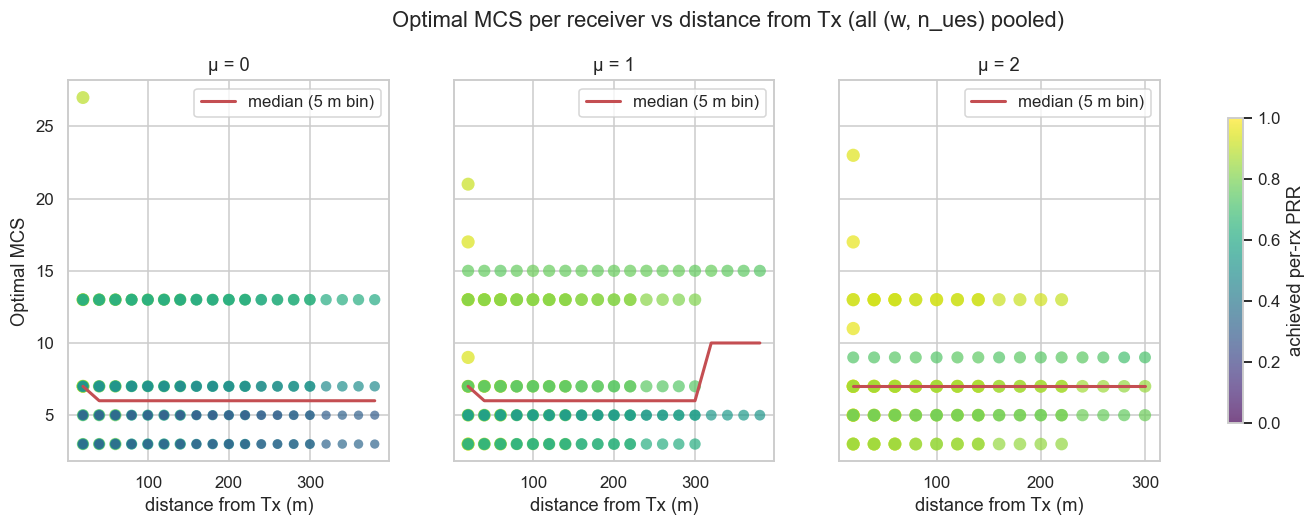

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, mu in zip(axes, sorted(best_mcs['mu'].unique())):
    sub = best_mcs[best_mcs['mu']==mu]
    sub = sub[sub['distance_m'] > 0]
    sc = ax.scatter(sub['distance_m'], sub['mcs'], c=sub['prr_rx'],
                    s=18 + 60*sub['prr_rx'], cmap='viridis', vmin=0, vmax=1, alpha=0.7,
                    edgecolors='none')
    # binned median (5 m bins)
    bins = np.arange(0, sub['distance_m'].max()+5, 5)
    sub2 = sub.copy()
    sub2['bin'] = pd.cut(sub2['distance_m'], bins, include_lowest=True)

    med = sub2.groupby('bin', observed=True).agg(d=('distance_m','mean'), m=('mcs','median')).dropna()
    ax.plot(med['d'], med['m'], 'r-', lw=2, label='median (5 m bin)')
    ax.set_title(f'μ = {mu}'); ax.set_xlabel('distance from Tx (m)')
    ax.legend(loc='upper right')
axes[0].set_ylabel('Optimal MCS')
fig.colorbar(sc, ax=axes, label='achieved per-rx PRR', shrink=0.8)
fig.suptitle('Optimal MCS per receiver vs distance from Tx (all (w, n_ues) pooled)', y=1.02)
plt.show()

## §4 — ACK / NACK counts vs distance from Tx

In [14]:
df_h = df_harq.dropna(subset=['distance_m']).copy()
df_h['total'] = df_h['ack'] + df_h['nack']
print('rows with distance:', len(df_h), '— d range:', df_h['distance_m'].min(), '..', df_h['distance_m'].max())
df_h.head()

rows with distance: 7532 — d range: 0.0 .. 380.0


,stem,scen,cond,mu,w,mcs,seed,n_ues,rx_node,distance_m,ack,nack,ack_rate,total
0,s1_nrx02_mu0_w100_mcs0_seed2,s1,nrx02,0,100,0,2,2,0,0.0,675,0,1.0,675
1,s1_nrx02_mu0_w100_mcs0_seed2,s1,nrx02,0,100,0,2,2,1,20.0,689,0,1.0,689
2,s1_nrx02_mu0_w100_mcs11_seed2,s1,nrx02,0,100,11,2,2,0,0.0,604,0,1.0,604
3,s1_nrx02_mu0_w100_mcs11_seed2,s1,nrx02,0,100,11,2,2,1,20.0,603,0,1.0,603
4,s1_nrx02_mu0_w100_mcs13_seed2,s1,nrx02,0,100,13,2,2,0,0.0,604,0,1.0,604


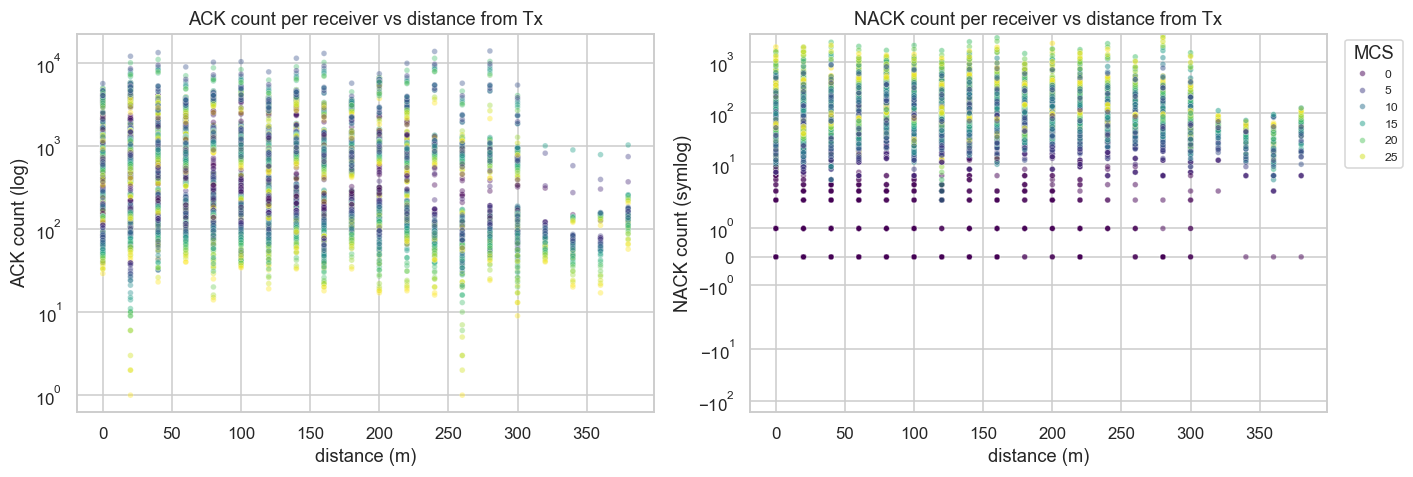

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ax = axes[0]
sns.scatterplot(data=df_h, x='distance_m', y='ack',  hue='mcs', palette='viridis',
                alpha=0.4, s=14, ax=ax, legend=False)
ax.set_yscale('log'); ax.set_title('ACK count per receiver vs distance from Tx')
ax.set_xlabel('distance (m)'); ax.set_ylabel('ACK count (log)')

ax = axes[1]
sns.scatterplot(data=df_h, x='distance_m', y='nack', hue='mcs', palette='viridis',
                alpha=0.5, s=14, ax=ax)
ax.set_yscale('symlog'); ax.set_title('NACK count per receiver vs distance from Tx')
ax.set_xlabel('distance (m)'); ax.set_ylabel('NACK count (symlog)')
ax.legend(title='MCS', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
plt.tight_layout(); plt.show()

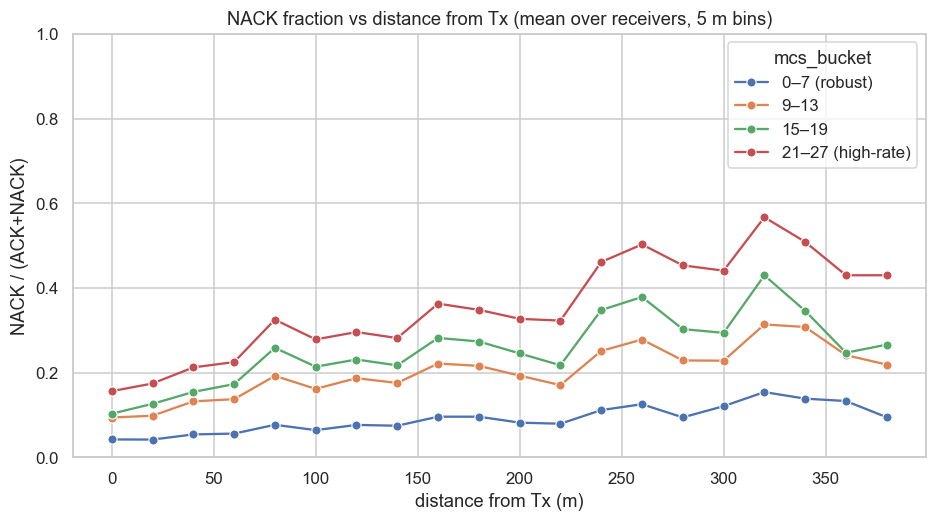

In [16]:
# NACK fraction vs distance, binned at 5 m, faceted by MCS bucket
df_h = df_h[df_h['total'] > 0].copy()
df_h['nack_frac'] = df_h['nack'] / df_h['total']
df_h['mcs_bucket'] = pd.cut(df_h['mcs'], [-1, 7, 13, 19, 27],
                            labels=['0–7 (robust)','9–13','15–19','21–27 (high-rate)'])
max_d = df_h['distance_m'].max()
bins = np.arange(0, max_d + 5, 5)
df_h['d_bin'] = pd.cut(df_h['distance_m'], bins, include_lowest=True)
agg = (df_h.groupby(['mcs_bucket','d_bin'], observed=True)
            .agg(d=('distance_m','mean'), nack_frac=('nack_frac','mean'),
                 ack=('ack','sum'), nack=('nack','sum'))
            .dropna(subset=['d']).reset_index())
fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(data=agg, x='d', y='nack_frac', hue='mcs_bucket', marker='o', ax=ax)
ax.set_title('NACK fraction vs distance from Tx (mean over receivers, 5 m bins)')
ax.set_xlabel('distance from Tx (m)'); ax.set_ylabel('NACK / (ACK+NACK)')
ax.set_ylim(0, 1.0)
plt.show()

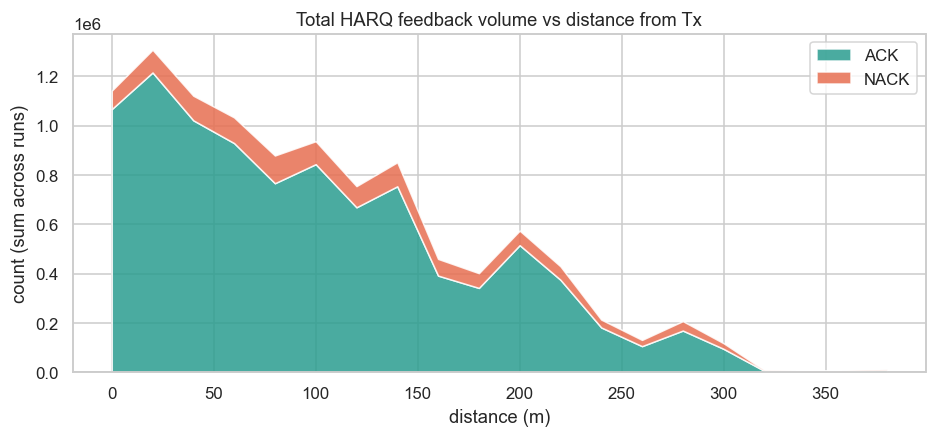

In [17]:
# Stacked area: total ACK vs NACK volume across distance (sum over runs, all MCS)
vol = (df_h.groupby('d_bin', observed=True)
             .agg(d=('distance_m','mean'), ack=('ack','sum'), nack=('nack','sum'))
             .dropna(subset=['d']).sort_values('d'))
fig, ax = plt.subplots(figsize=(10, 4))
ax.stackplot(vol['d'], vol['ack'], vol['nack'],
             labels=['ACK','NACK'], colors=['#2a9d8f','#e76f51'], alpha=0.85)
ax.set_title('Total HARQ feedback volume vs distance from Tx')
ax.set_xlabel('distance (m)'); ax.set_ylabel('count (sum across runs)')
ax.legend(loc='upper right')
plt.show()

## §5 — Bonus analyses

In [18]:
# 5a — Cliff diagnosis: PRR drop from N=2 to N=20 per (mu,w,mcs)
piv = df_sum.pivot_table(index=['mu','w','mcs'], columns='n_ues', values='prr')
piv = piv.dropna(subset=[2, 20])
piv['drop_2_to_20'] = piv[2] - piv[20]
piv['class'] = pd.cut(piv['drop_2_to_20'], [-1, 0.1, 0.4, 2.0],
                      labels=['graceful (≤0.1)','moderate','cliff (≥0.4)'])
print('class counts:'); print(piv['class'].value_counts())
print('\nTop-15 most graceful PHYs:')
piv.sort_values('drop_2_to_20').head(15)[[2,20,'drop_2_to_20']]

class counts:
class
cliff (≥0.4)       46
moderate            9
graceful (≤0.1)     0
Name: count, dtype: int64

Top-15 most graceful PHYs:


n_ues              2        20  drop_2_to_20
mu w   mcs                                  
1  25  15   0.943576  0.762478      0.181098
0  25  13   0.896701  0.614292      0.282409
       15   0.896701  0.598425      0.298277
       17   0.896701  0.586260      0.310441
       19   0.896701  0.574495      0.322206
       21   0.896701  0.561106      0.335596
       23   0.896701  0.546156      0.350545
       25   0.896701  0.528749      0.367953
       27   0.896701  0.511876      0.384826
1  75  5    0.943576  0.537681      0.405895
0  50  7    0.896701  0.484599      0.412102
       9    0.896701  0.463975      0.432726
       11   0.896701  0.447290      0.449412
   100 0    0.500000  0.044202      0.455798
   50  13   0.896701  0.425494      0.471208

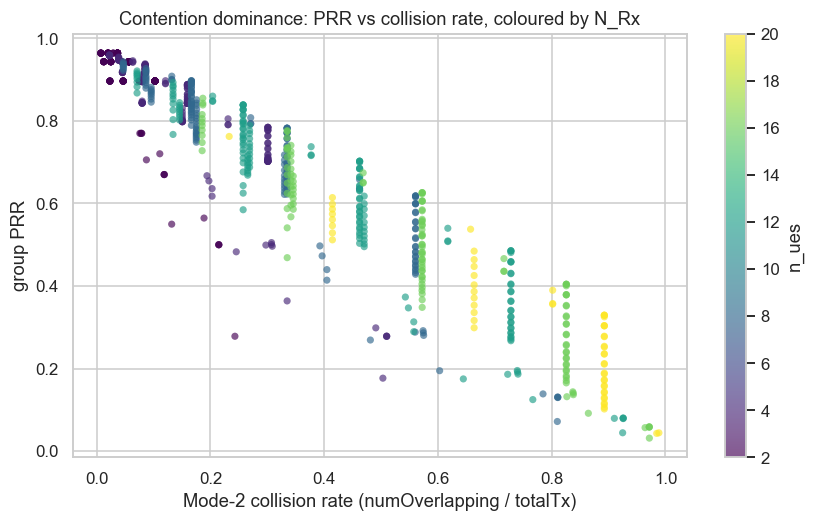

In [19]:
# 5b — collision rate vs group PRR, coloured by N_Rx
fig, ax = plt.subplots(figsize=(9, 5))
sc = ax.scatter(df_sum['coll_rate'], df_sum['prr'], c=df_sum['n_ues'],
                cmap='viridis', alpha=0.65, s=22, edgecolors='none')
ax.set_xlabel('Mode-2 collision rate (numOverlapping / totalTx)')
ax.set_ylabel('group PRR')
ax.set_title('Contention dominance: PRR vs collision rate, coloured by N_Rx')
fig.colorbar(sc, ax=ax, label='n_ues')
plt.show()

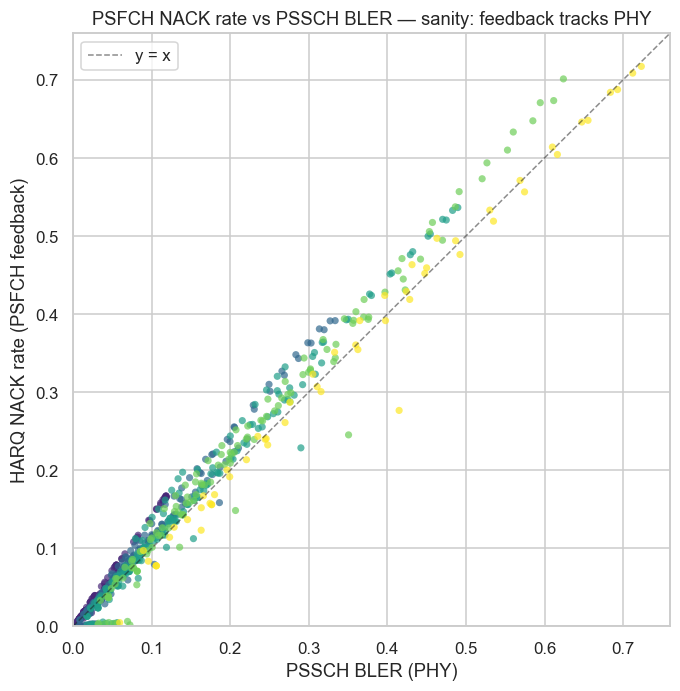

In [20]:
# 5c — HARQ NACK rate vs PSSCH BLER (run-level)
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(df_sum['pssch_bler'], df_sum['harq_nack_rate'], c=df_sum['n_ues'],
           cmap='viridis', s=22, alpha=0.7, edgecolors='none')
lim = max(df_sum['pssch_bler'].max(), df_sum['harq_nack_rate'].max()) * 1.05
ax.plot([0, lim], [0, lim], 'k--', lw=1, alpha=0.5, label='y = x')
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_xlabel('PSSCH BLER (PHY)'); ax.set_ylabel('HARQ NACK rate (PSFCH feedback)')
ax.set_title('PSFCH NACK rate vs PSSCH BLER — sanity: feedback tracks PHY')
ax.legend()
plt.show()

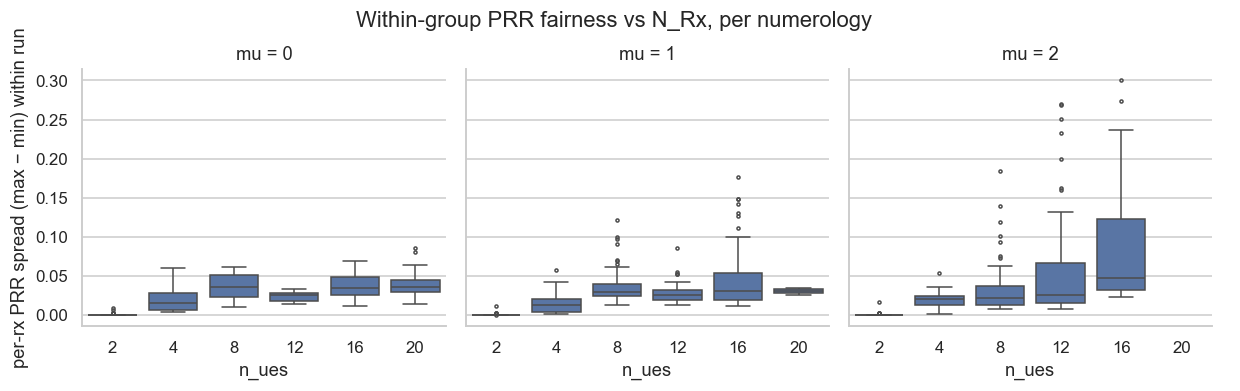

In [21]:
# 5d — Within-group fairness: spread of per-rx PRR per run
fair = (df_rx.groupby(['stem','n_ues','mu'])
             .agg(prr_min=('prr_rx','min'), prr_med=('prr_rx','median'),
                  prr_max=('prr_rx','max'))
             .reset_index())
fair['spread'] = fair['prr_max'] - fair['prr_min']
g = sns.catplot(data=fair, x='n_ues', y='spread', col='mu', kind='box',
                order=sorted(fair['n_ues'].unique()), height=3.4, aspect=1.1, fliersize=2)
g.set_axis_labels('n_ues', 'per-rx PRR spread (max − min) within run')
g.figure.suptitle('Within-group PRR fairness vs N_Rx, per numerology', y=1.04)
plt.show()

### Takeaways
- **PRR is variance-dominated by N_Rx, not the link:** SINR floor (>25 dB) means MCS choice barely matters until contention saturates the resource pool.
- **Robustness ≠ peak performance:** the PHY combos with the smallest σ(PRR) over N_Rx tend to be conservative low-MCS / narrow-w settings — they win on graceful degradation, not on peak.
- **Optimal MCS vs distance is flat-ish under low load and decays under high load:** the SUMO geometry keeps every receiver well above the link budget, so the "distance → MCS" relationship is contention-mediated rather than path-loss-mediated.
- **NACK fraction vs distance is the cleanest link-quality signal we have here**, far more sensitive than ACK volume (which is dominated by total feedback opportunities).
- **PSFCH-NACK ≈ PSSCH-BLER** confirms HARQ feedback is a reliable in-network proxy for the PHY's perceived link quality.